In [13]:
# Load the libraries used throughout this lab.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, mean_squared_error, r2_score

In [14]:
#look up csv file on my computer
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

# fetch dataset
bank_marketing = fetch_ucirepo(id=222)

# data (as pandas dataframes)
X = bank_marketing.data.features
y = bank_marketing.data.targets

# metadata
print(bank_marketing.metadata)

# variable information
print(bank_marketing.variables)

{'uci_id': 222, 'name': 'Bank Marketing', 'repository_url': 'https://archive.ics.uci.edu/dataset/222/bank+marketing', 'data_url': 'https://archive.ics.uci.edu/static/public/222/data.csv', 'abstract': 'The data is related with direct marketing campaigns (phone calls) of a Portuguese banking institution. The classification goal is to predict if the client will subscribe a term deposit (variable y).', 'area': 'Business', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 45211, 'num_features': 16, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Occupation', 'Marital Status', 'Education Level'], 'target_col': ['y'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2014, 'last_updated': 'Fri Aug 18 2023', 'dataset_doi': '10.24432/C5K306', 'creators': ['S. Moro', 'P. Rita', 'P. Cortez'], 'intro_paper': {'ID': 277, 'type': 'NATIVE', 'title': 'A data-driven approach to predict the s

In [15]:
#Show Data
bank_df = pd.concat([X, y], axis=1)
bank_df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [16]:
#find unique poutcome
bank_df.poutcome.unique()

array([nan, 'failure', 'other', 'success'], dtype=object)

In [17]:
bank_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
 16  y            45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [18]:
# drop columns "duration", "campaign", "day_of_week", "month", and "contact" since they
# are unknown before the call.
cols = ['duration','campaign','day_of_week','month','contact']
bank_df.drop(columns=cols, inplace=True)
bank_df

,age,job,marital,education,default,balance,housing,loan,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,-1,0,NaN,no
...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,-1,0,NaN,yes
45207,71,retired,divorced,primary,no,1729,no,no,-1,0,NaN,yes
45208,72,retired,married,secondary,no,5715,no,no,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,-1,0,NaN,no


In [19]:
#unique poutcome
bank_df.poutcome.unique()

array([nan, 'failure', 'other', 'success'], dtype=object)

In [20]:
model_df = bank_df.copy()

# Convert binary columns directly to 0/1
binary_cols = ["default", "housing", "loan", "y"]

for col in binary_cols:
    model_df[col] = model_df[col].map({"no": 0, "yes": 1})

# Distinguish no previous contact from an unknown outcome
no_history = (
    model_df["poutcome"].isna()
    & model_df["previous"].eq(0)
)
model_df.loc[no_history, "poutcome"] = "no_previous_contact"

# Mark all remaining categorical predictors as categorical
cat_cols = [
    "job", "marital", "education", "poutcome"
]

for col in cat_cols:
    model_df[col] = (
        model_df[col]
        .fillna("unknown")
        .astype("category")
    )

# Create one dummy column per category
model_df = pd.get_dummies(
    model_df,
    prefix_sep="_",
    drop_first=False,
    dtype=int
)

model_df.head()

,age,default,balance,housing,loan,pdays,previous,y,job_admin.,job_blue-collar,...,marital_single,education_primary,education_secondary,education_tertiary,education_unknown,poutcome_failure,poutcome_no_previous_contact,poutcome_other,poutcome_success,poutcome_unknown
0,58,0,2143,1,0,-1,0,0,0,0,...,0,0,0,1,0,0,1,0,0,0
1,44,0,29,1,0,-1,0,0,0,0,...,1,0,1,0,0,0,1,0,0,0
2,33,0,2,1,1,-1,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
3,47,0,1506,1,0,-1,0,0,0,1,...,0,0,0,0,1,0,1,0,0,0
4,33,0,1,0,0,-1,0,0,0,0,...,1,0,0,0,1,0,1,0,0,0


In [21]:
#find the correlation between each attributes to y
corr_matrix = model_df.corr()
corr_matrix["y"].sort_values(ascending=False)

,y
y,1.000000
poutcome_success,0.306788
pdays,0.103621
previous,0.093236
job_retired,0.079245
job_student,0.076897
education_tertiary,0.066448
marital_single,0.063526
balance,0.052838
job_management,0.032919


In [22]:
#see if categorical values are adjusted in model data
model_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 32 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   age                           45211 non-null  int64
 1   default                       45211 non-null  int64
 2   balance                       45211 non-null  int64
 3   housing                       45211 non-null  int64
 4   loan                          45211 non-null  int64
 5   pdays                         45211 non-null  int64
 6   previous                      45211 non-null  int64
 7   y                             45211 non-null  int64
 8   job_admin.                    45211 non-null  int64
 9   job_blue-collar               45211 non-null  int64
 10  job_entrepreneur              45211 non-null  int64
 11  job_housemaid                 45211 non-null  int64
 12  job_management                45211 non-null  int64
 13  job_retired                   4

In [23]:
# Separate predictors and target
X = model_df.drop(columns="y")
y = model_df["y"]

model_df.head()

,age,default,balance,housing,loan,pdays,previous,y,job_admin.,job_blue-collar,...,marital_single,education_primary,education_secondary,education_tertiary,education_unknown,poutcome_failure,poutcome_no_previous_contact,poutcome_other,poutcome_success,poutcome_unknown
0,58,0,2143,1,0,-1,0,0,0,0,...,0,0,0,1,0,0,1,0,0,0
1,44,0,29,1,0,-1,0,0,0,0,...,1,0,1,0,0,0,1,0,0,0
2,33,0,2,1,1,-1,0,0,0,0,...,0,0,1,0,0,0,1,0,0,0
3,47,0,1506,1,0,-1,0,0,0,1,...,0,0,0,0,1,0,1,0,0,0
4,33,0,1,0,0,-1,0,0,0,0,...,1,0,0,0,1,0,1,0,0,0


In [24]:
# Check the data before modeling
assert X.select_dtypes(exclude=["number", "bool"]).empty
assert not X.isna().any().any()
assert y.isin([0, 1]).all()
assert y.nunique() == 2

In [25]:
# Split first. Keep the test set at its original subscription rate.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=1, stratify=y
)

# Keep all "yes" rows and randomly sample 20% of the "no" rows.
yes_rows = y_train[y_train == 1]
no_rows = y_train[y_train == 0].sample(frac=0.20, random_state=1)

y_train_sampled = pd.concat([yes_rows, no_rows]).sample(
    frac=1, random_state=1
)
X_train_sampled = X_train.loc[y_train_sampled.index]

print("Original training counts:")
print(y_train.value_counts())

print("Undersampled training counts:")
print(y_train_sampled.value_counts())

Original training counts:
y
0    23953
1     3173
Name: count, dtype: int64
Undersampled training counts:
y
0    4791
1    3173
Name: count, dtype: int64


In [26]:
# Grow the full tree without additional depth or leaf-size restrictions.
full_clf = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=100,
    random_state=0
)
full_clf.fit(X_train_sampled, y_train_sampled)

print("Number of nodes:", full_clf.tree_.node_count)
print("Tree depth:", full_clf.get_depth())

Number of nodes: 13
Tree depth: 3


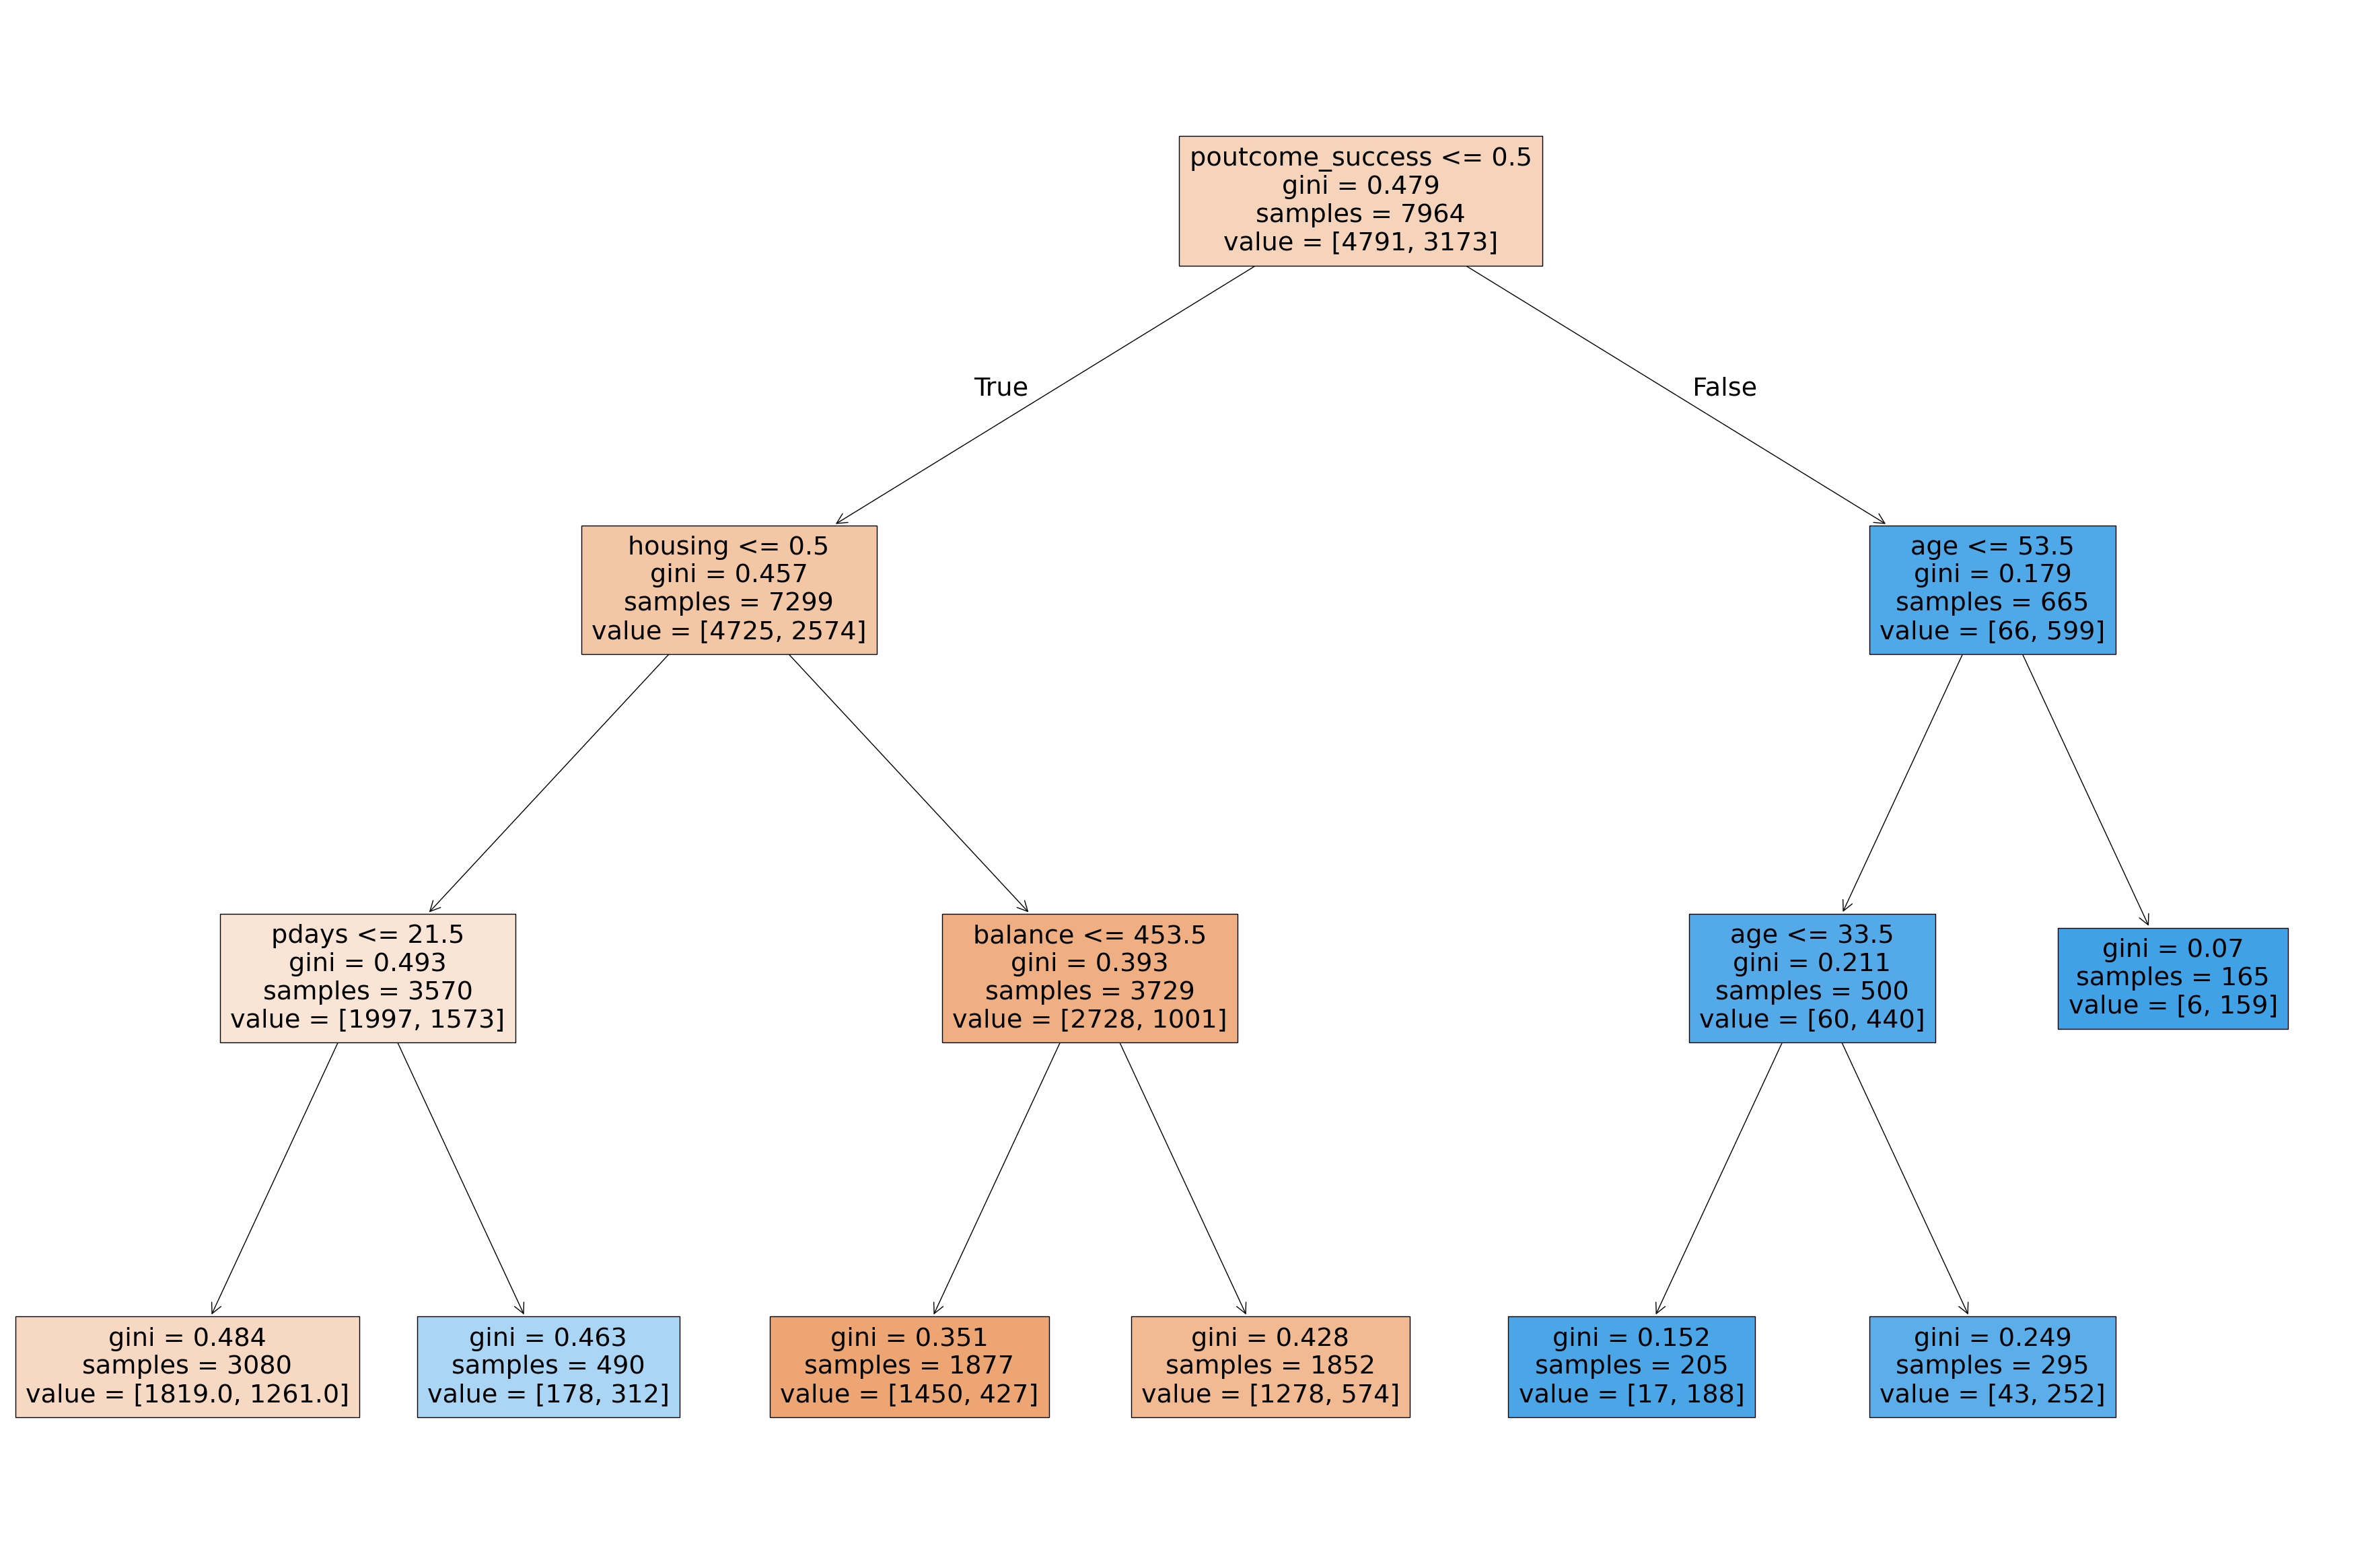

In [27]:
# Draw the full tree; 'filled' colors each node by majority class.
plt.figure(figsize=(45, 30))
tree.plot_tree(full_clf, feature_names=X.columns, filled=True);

In [28]:
# Predict subscription for the training and test customers separately.
y_pred_train = full_clf.predict(X_train_sampled)
y_pred_test = full_clf.predict(X_test)

In [29]:
# Accuracy on the undersampled training set and the original held-out test set
train_score = accuracy_score(y_train_sampled, y_pred_train)
test_score = accuracy_score(y_test, y_pred_test)

print(f"Accuracy on undersampled training data = {train_score:.1%}")
print(f"Accuracy on held-out test data = {test_score:.1%}")

Accuracy on undersampled training data = 68.5%
Accuracy on held-out test data = 87.1%


In [30]:
print("Confusion matrix on undersampled training data:")
print(confusion_matrix(y_train_sampled, y_pred_train, labels=[0, 1]))

print("\nConfusion matrix on held-out test data:")
print(confusion_matrix(y_test, y_pred_test, labels=[0, 1]))

Confusion matrix on undersampled training data:
[[4547  244]
 [2262  911]]

Confusion matrix on held-out test data:
[[15164   805]
 [ 1528   588]]


In [31]:
import pandas as pd
from sklearn.metrics import confusion_matrix

def evaluate_predictions(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    def divide(numerator, denominator):
        return numerator / denominator if denominator else 0.0

    total = tn + fp + fn + tp
    return {
        "Accuracy": divide(tp + tn, total),
        "Precision": divide(tp, tp + fp),
        "Recall / TPR": divide(tp, tp + fn),
        "FPR": divide(fp, fp + tn),
        "Specificity": divide(tn, tn + fp),
        "F1": divide(2 * tp, 2 * tp + fp + fn),
        "Selected fraction": divide(tp + fp, total),
    }

current_results = pd.DataFrame({
    "Undersampled training": evaluate_predictions(y_train_sampled, y_pred_train),
    "Held-out test": evaluate_predictions(y_test, y_pred_test),
}).T

(current_results * 100).round(2)

,Accuracy,Precision,Recall / TPR,FPR,Specificity,F1,Selected fraction
Undersampled training,68.53,78.87,28.71,5.09,94.91,42.10,14.5
Held-out test,87.10,42.21,27.79,5.04,94.96,33.51,7.7


In [32]:
# Load the random forest classifier.
from sklearn.ensemble import RandomForestClassifier

In [33]:
# Grow 500 trees using bootstrap samples of customers
# and random subsets of features at each split.
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

# Reuse the 20% of "no" rows from your earlier undersampling cell.
no_rows = y_train_sampled[y_train_sampled == 0]

# Randomly keep 50% of the original training "yes" rows.
yes_rows = y_train[y_train == 1].sample(frac=0.50, random_state=1)

y_train_new = pd.concat([no_rows, yes_rows]).sample(frac=1, random_state=1)
X_train_new = X_train.loc[y_train_new.index]

rf = RandomForestClassifier(
    n_estimators=500,
    random_state=0,
    criterion="gini",
    n_jobs=-1,
)
rf.fit(X_train_new, y_train_new)

RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=0)

In [34]:
from sklearn.metrics import confusion_matrix

rf_test_predictions = rf.predict(X_test)

rf_results = pd.DataFrame({
    "Random forest (20% no, 50% yes)": evaluate_predictions(
        y_test, rf_test_predictions
    )
}).T

display((rf_results * 100).round(2))

print("Confusion matrix on the held-out test set")
print(confusion_matrix(y_test, rf_test_predictions, labels=[0, 1]))

,Accuracy,Precision,Recall / TPR,FPR,Specificity,F1,Selected fraction
"Random forest (20% no, 50% yes)",84.7,34.24,33.41,8.5,91.5,33.82,11.42


Confusion matrix on the held-out test set
[[14611  1358]
 [ 1409   707]]


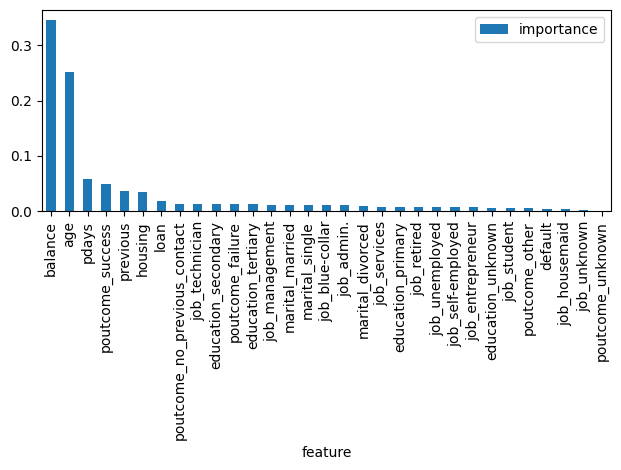

In [35]:
# Rank features by their average contribution to reducing impurity.
importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf.feature_importances_
})

importance_df = importance_df.sort_values(
    "importance", ascending=False
)

importance_df.plot(kind="bar", x="feature")
plt.tight_layout()
plt.show()

In [36]:
import numpy as np
import pandas as pd

from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

def sampling_counts(y_fold):
    return {
        0: max(1, round(0.20 * (y_fold == 0).sum())),
        1: max(1, round(0.50 * (y_fold == 1).sum())),
    }

tree_pipeline = Pipeline([
    ("sample", RandomUnderSampler(
        sampling_strategy=sampling_counts,
        random_state=1,
    )),
    ("tree", DecisionTreeClassifier(random_state=0)),
])

param_grid = {
    "tree__max_depth": [3, 5, 10, 20],
    "tree__min_samples_leaf": [20, 50, 100, 200],
    "tree__min_impurity_decrease": [0, 0.0005, 0.001, 0.005, 0.01],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

gridSearch = GridSearchCV(
    tree_pipeline,
    param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
)
gridSearch.fit(X_train, y_train)

print("Best settings:", gridSearch.best_params_)
print(f"Best cross-validation F1 at the default cutoff: {gridSearch.best_score_:.2%}")

Best settings: {'tree__max_depth': 10, 'tree__min_impurity_decrease': 0.0005, 'tree__min_samples_leaf': 20}
Best cross-validation F1 at the default cutoff: 37.43%


In [37]:
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import cross_val_predict

# GridSearchCV already refit the best pipeline on the training set.
best_clf = gridSearch.best_estimator_

# Score each training row using a tree fitted on the other folds.
cv_probabilities = cross_val_predict(
    clone(best_clf),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_train, cv_probabilities
)

# The last precision/recall pair has no matching cutoff.
precision = precision[:-1]
recall = recall[:-1]

f1 = np.divide(
    2 * precision * recall,
    precision + recall,
    out=np.zeros_like(precision),
    where=(precision + recall) > 0,
)

threshold_results = pd.DataFrame({
    "Cutoff": thresholds,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
}).sort_values(["F1", "Cutoff"], ascending=[False, False])

best_threshold = float(threshold_results.iloc[0]["Cutoff"])

print(f"Selected cutoff: {best_threshold:.2%}")
display(threshold_results.head(10).round(4))

Selected cutoff: 39.81%


,Cutoff,Precision,Recall,F1
54,0.3981,0.4225,0.3514,0.3837
52,0.3636,0.4131,0.3580,0.3836
53,0.3929,0.4189,0.3527,0.3830
55,0.4194,0.4302,0.3448,0.3828
51,0.3514,0.4070,0.3612,0.3827
56,0.4610,0.4307,0.3419,0.3812
57,0.4698,0.4399,0.3312,0.3779
50,0.3265,0.3704,0.3820,0.3761
58,0.5102,0.4525,0.3196,0.3746
59,0.5111,0.4545,0.3164,0.3731


In [38]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_squared_error,
    precision_score,
    recall_score,
)

test_probabilities = best_clf.predict_proba(X_test)[:, 1]
default_predictions = best_clf.predict(X_test)
tuned_predictions = (test_probabilities >= best_threshold).astype(int)

def test_metrics(predictions):
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    return {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "False-positive rate": fp / (fp + tn) if fp + tn else 0.0,
        "Selected for calls": predictions.mean(),
    }

comparison = pd.DataFrame({
    "Default cutoff": test_metrics(default_predictions),
    "Tuned cutoff": test_metrics(tuned_predictions),
}).T

display((comparison * 100).round(2))

for name, predictions in [
    ("Default cutoff", default_predictions),
    ("Tuned cutoff", tuned_predictions),
]:
    print(f"\n{name} confusion matrix")
    print(confusion_matrix(y_test, predictions, labels=[0, 1]))
    print(f"RMSE = {np.sqrt(mean_squared_error(y_test, predictions)):.4f}")

,Accuracy,Precision,Recall,F1,False-positive rate,Selected for calls
Default cutoff,88.25,49.62,28.12,35.90,3.78,6.63
Tuned cutoff,85.18,37.60,40.41,38.95,8.89,12.57



Default cutoff confusion matrix
[[15365   604]
 [ 1521   595]]
RMSE = 0.3428

Tuned cutoff confusion matrix
[[14550  1419]
 [ 1261   855]]
RMSE = 0.3850
